<a href="https://colab.research.google.com/github/kashishgandhi-hub/market-pipeline/blob/main/asx200_pipeline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install -q yfinance==1.7.0 duckdb==2.0.0

In [2]:
import yfinance as yf

df = yf.download("^AXJO", start="2024-01-01")
df.head()


[*********************100%***********************]  1 of 1 completed


Price,Close,High,Low,Open,Volume
Ticker,^AXJO,^AXJO,^AXJO,^AXJO,^AXJO
Date,,,,,
2024-01-02,7627.799805,7632.700195,7584.500000,7590.799805,307500
2024-01-03,7523.200195,7627.799805,7521.899902,7627.799805,475500
2024-01-04,7494.100098,7529.899902,7481.100098,7523.200195,469800
2024-01-05,7489.100098,7514.299805,7488.200195,7492.500000,437400
2024-01-08,7451.500000,7504.200195,7441.799805,7489.100098,526400


In [3]:
df = yf.download(
    "^AXJO",
    start="2024-01-01",
    auto_adjust=False,
    multi_level_index=False,
    progress=False,
)
df.head()

,Adj Close,Close,High,Low,Open,Volume
Date,,,,,,
2024-01-02,7627.799805,7627.799805,7632.700195,7584.500000,7590.799805,307500
2024-01-03,7523.200195,7523.200195,7627.799805,7521.899902,7627.799805,475500
2024-01-04,7494.100098,7494.100098,7529.899902,7481.100098,7523.200195,469800
2024-01-05,7489.100098,7489.100098,7514.299805,7488.200195,7492.500000,437400
2024-01-08,7451.500000,7451.500000,7504.200195,7441.799805,7489.100098,526400


In [4]:
bad = yf.download("^NOTREAL", start="2024-01-01", progress=False)

print("Did it crash? No, we got here.")
print("Rows received:", len(bad))

ERROR:yfinance:HTTP Error 404: {"quoteSummary":{"result":null,"error":{"code":"Not Found","description":"Quote not found for symbol: ^NOTREAL"}}}
ERROR:yfinance:$^NOTREAL: possibly delisted; no timezone found
ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['^NOTREAL']: possibly delisted; no timezone found


Did it crash? No, we got here.
Rows received: 0


In [5]:
class FetchError(Exception):
    pass

def fetch_index(ticker, start="2024-01-01"):
    df = yf.download(
        ticker,
        start=start,
        auto_adjust=False,
        multi_level_index=False,
        progress=False,
    )
    if df.empty:
        raise FetchError(f"Yahoo returned no rows for {ticker}")
    return df.reset_index()

raw = fetch_index("^AXJO")
print("Rows:", len(raw))
raw.head()

Rows: 715


,Date,Adj Close,Close,High,Low,Open,Volume
0,2024-01-02,7627.799805,7627.799805,7632.700195,7584.500000,7590.799805,307500
1,2024-01-03,7523.200195,7523.200195,7627.799805,7521.899902,7627.799805,475500
2,2024-01-04,7494.100098,7494.100098,7529.899902,7481.100098,7523.200195,469800
3,2024-01-05,7489.100098,7489.100098,7514.299805,7488.200195,7492.500000,437400
4,2024-01-08,7451.500000,7451.500000,7504.200195,7441.799805,7489.100098,526400


In [6]:
import time

def fetch_with_retry(ticker, retries=4, wait=1):
    for attempt in range(1, retries + 1):
        try:
            df = fetch_index(ticker)
            print(f"Attempt {attempt}: success, {len(df)} rows")
            return df, attempt
        except Exception as e:
            print(f"Attempt {attempt} failed: {e}")
            if attempt < retries:
                pause = wait * 2 ** (attempt - 1)
                print(f"  waiting {pause}s before retrying")
                time.sleep(pause)
    raise FetchError(f"Gave up on {ticker} after {retries} attempts")

In [7]:
raw, attempts = fetch_with_retry("^AXJO")

try:
    fetch_with_retry("^NOTREAL")
except FetchError as e:
    print("PIPELINE STOPPED:", e)

Attempt 1: success, 715 rows


ERROR:yfinance:HTTP Error 404: {"quoteSummary":{"result":null,"error":{"code":"Not Found","description":"Quote not found for symbol: ^NOTREAL"}}}
ERROR:yfinance:$^NOTREAL: possibly delisted; no timezone found
ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['^NOTREAL']: possibly delisted; no timezone found


Attempt 1 failed: Yahoo returned no rows for ^NOTREAL
  waiting 1s before retrying


ERROR:yfinance:$^NOTREAL: possibly delisted; no timezone found
ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['^NOTREAL']: possibly delisted; no timezone found


Attempt 2 failed: Yahoo returned no rows for ^NOTREAL
  waiting 2s before retrying


ERROR:yfinance:$^NOTREAL: possibly delisted; no timezone found
ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['^NOTREAL']: possibly delisted; no timezone found


Attempt 3 failed: Yahoo returned no rows for ^NOTREAL
  waiting 4s before retrying


ERROR:yfinance:$^NOTREAL: possibly delisted; no timezone found
ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['^NOTREAL']: possibly delisted; no timezone found


Attempt 4 failed: Yahoo returned no rows for ^NOTREAL
PIPELINE STOPPED: Gave up on ^NOTREAL after 4 attempts


In [8]:
import os, json, hashlib, uuid
from datetime import datetime, timezone

def new_run_id():
    stamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S")
    return stamp + "-" + uuid.uuid4().hex[:6]

def land_raw(df, source, run_id):
    load_date = datetime.now(timezone.utc).strftime("%Y-%m-%d")
    folder = f"data/raw/source={source}/load_date={load_date}"
    os.makedirs(folder, exist_ok=True)

    path = f"{folder}/{run_id}.csv"
    df.to_csv(path, index=False)

    with open(path, "rb") as f:
        sha = hashlib.sha256(f.read()).hexdigest()

    manifest = {
        "run_id": run_id,
        "source": source,
        "rows": len(df),
        "columns": list(df.columns),
        "sha256": sha,
        "landed_at": datetime.now(timezone.utc).isoformat(),
    }
    with open(f"{folder}/{run_id}.manifest.json", "w") as f:
        json.dump(manifest, f, indent=2)

    return path, sha

run_id = new_run_id()
raw_path, raw_sha = land_raw(raw, "asx200", run_id)
print("Run ID:", run_id)
print("Saved to:", raw_path)
print("Fingerprint:", raw_sha)

Run ID: 20261026T120315-4e78fa
Saved to: data/raw/source=asx200/load_date=2026-10-26/20261026T120315-4e78fa.csv
Fingerprint: 35845786e9ce75395b46a2526fafccedd320d0bb4c6e04a4a1fc72726ed6460b


In [9]:
REQUIRED_COLUMNS = ["date", "open", "high", "low", "close", "volume"]

class SchemaError(Exception):
    pass

def normalise(df):
    df = df.copy()
    df.columns = [str(c).strip().lower().replace(" ", "_") for c in df.columns]
    return df

def check_schema(df):
    missing = [c for c in REQUIRED_COLUMNS if c not in df.columns]
    if missing:
        raise SchemaError(f"missing {missing}, got {list(df.columns)}")

# 1. Real data: should pass
df = normalise(raw)
check_schema(df)
print("Schema OK:", list(df.columns))

# 2. Pretend Yahoo renamed a column
broken = raw.rename(columns={"Close": "Last Price"})
try:
    check_schema(normalise(broken))
except SchemaError as e:
    print("SCHEMA CHANGE DETECTED:", e)

Schema OK: ['date', 'adj_close', 'close', 'high', 'low', 'open', 'volume']
SCHEMA CHANGE DETECTED: missing ['close'], got ['date', 'adj_close', 'last_price', 'high', 'low', 'open', 'volume']


In [10]:
import pandas as pd

def validate_rows(df):
    df = df.copy()
    df["date"] = pd.to_datetime(df["date"], errors="coerce")
    reasons = pd.Series("", index=df.index)

    def flag(mask, code):
        reasons[mask] = reasons[mask] + code + ","

    prices = ["open", "high", "low", "close"]
    flag(df["date"].isna(), "BAD_DATE")
    flag(df[prices].isna().any(axis=1), "NULL_PRICE")
    flag((df[prices] <= 0).any(axis=1), "NON_POSITIVE_PRICE")
    flag(df["high"] < df["low"], "HIGH_LT_LOW")
    flag(df["volume"] < 0, "NEGATIVE_VOLUME")
    flag(df.duplicated(subset=["date"], keep="first"), "DUPLICATE_DATE")

    bad = reasons != ""
    passed = df[~bad]
    quarantined = df[bad].assign(reason_codes=reasons[bad].str.rstrip(","))
    return passed, quarantined

passed, quarantined = validate_rows(df)
print("Real data -> received:", len(df), "passed:", len(passed), "quarantined:", len(quarantined))

Real data -> received: 715 passed: 715 quarantined: 0


In [11]:
test = df.copy()
test.loc[5, "close"] = None                       # missing price
test.loc[10, "high"] = test.loc[10, "low"] - 50   # high below low, impossible
test.loc[15, "volume"] = -100                     # negative volume
test = pd.concat([test, test.iloc[[20]]], ignore_index=True)  # duplicate a day

p, q = validate_rows(test)
print("Broken data -> received:", len(test), "passed:", len(p), "quarantined:", len(q))
assert len(test) == len(p) + len(q), "ROWS WENT MISSING"
print("No rows lost.")
q[["date", "close", "high", "low", "volume", "reason_codes"]]

Broken data -> received: 716 passed: 712 quarantined: 4
No rows lost.


,date,close,high,low,volume,reason_codes
5,2024-01-09,NaN,7541.899902,7464.700195,530600,NULL_PRICE
10,2024-01-16,7414.799805,7352.299805,7402.299805,570700,HIGH_LT_LOW
15,2024-01-23,7514.899902,7530.299805,7476.600098,-100,NEGATIVE_VOLUME
715,2024-01-31,7680.700195,7682.299805,7570.200195,0,DUPLICATE_DATE


In [12]:
zero_vol = df[df["volume"] == 0]
print("Days with zero volume:", len(zero_vol), "out of", len(df))
zero_vol[["date", "close", "volume"]].tail(10)

Days with zero volume: 5 out of 715


,date,close,volume
20,2024-01-31,7680.700195,0
38,2024-02-26,7652.799805,0
177,2024-09-12,8075.700195,0
629,2026-06-29,8823.400391,0
714,2026-10-26,8809.900391,0


In [13]:
def dq_warnings(df):
    warnings = []
    zero = df[df["volume"] == 0]
    for d in zero["date"]:
        warnings.append(f"ZERO_VOLUME on {d.date()}")
    return warnings

warnings = dq_warnings(passed)
print(len(warnings), "warnings:")
for w in warnings:
    print(" -", w)

5 warnings:
 - ZERO_VOLUME on 2024-01-31
 - ZERO_VOLUME on 2024-02-26
 - ZERO_VOLUME on 2024-09-12
 - ZERO_VOLUME on 2026-06-29
 - ZERO_VOLUME on 2026-10-26


In [14]:
import duckdb

con = duckdb.connect("data/warehouse.duckdb")

con.execute("""
CREATE TABLE IF NOT EXISTS staging_prices (
    source VARCHAR, date DATE, open DOUBLE, high DOUBLE, low DOUBLE,
    close DOUBLE, volume DOUBLE, run_id VARCHAR,
    PRIMARY KEY (source, date)
);
CREATE TABLE IF NOT EXISTS quarantine (
    run_id VARCHAR, source VARCHAR, record VARCHAR, reason_codes VARCHAR,
    resolved BOOLEAN DEFAULT FALSE
);
CREATE TABLE IF NOT EXISTS dq_runs (
    run_id VARCHAR PRIMARY KEY, source VARCHAR, run_at TIMESTAMP,
    status VARCHAR, attempts INTEGER, rows_received INTEGER,
    rows_passed INTEGER, rows_quarantined INTEGER, warnings INTEGER,
    raw_sha256 VARCHAR
);
""")
print("Tables ready")

def save_run(con, source, run_id, passed, quarantined, attempts, raw_sha, warnings):
    stg = passed[["date", "open", "high", "low", "close", "volume"]].copy()
    stg.insert(0, "source", source)
    stg["run_id"] = run_id
    con.register("incoming", stg)
    con.execute("""
        INSERT OR REPLACE INTO staging_prices
        SELECT source, CAST(date AS DATE), open, high, low, close, volume, run_id
        FROM incoming
    """)
    con.unregister("incoming")

    for _, row in quarantined.iterrows():
        con.execute(
            "INSERT INTO quarantine (run_id, source, record, reason_codes) VALUES (?, ?, ?, ?)",
            [run_id, source, row.drop("reason_codes").to_json(date_format="iso"), row["reason_codes"]],
        )

    status = "SUCCESS"
    if len(quarantined):
        status = "SUCCESS_WITH_QUARANTINE"
    if warnings:
        status += "_WARN"

    con.execute(
        "INSERT INTO dq_runs VALUES (?, ?, current_timestamp, ?, ?, ?, ?, ?, ?, ?)",
        [run_id, source, status, attempts, len(passed) + len(quarantined),
         len(passed), len(quarantined), len(warnings), raw_sha],
    )
    return status

Tables ready


In [15]:
s1 = save_run(con, "asx200", run_id, passed, quarantined, attempts, raw_sha, warnings)
print("Run 1:", s1)

run_id_2 = new_run_id()
s2 = save_run(con, "asx200", run_id_2, p, q, 1, "test-data", [])
print("Run 2:", s2)

display(con.sql("select count(*) as rows_in_staging, count(distinct date) as distinct_days from staging_prices").df())
display(con.sql("select status, attempts, rows_received, rows_passed, rows_quarantined, warnings from dq_runs").df())
display(con.sql("select reason_codes, record from quarantine").df())

Run 1: SUCCESS_WARN
Run 2: SUCCESS_WITH_QUARANTINE


,rows_in_staging,distinct_days
0,715,715


,status,attempts,rows_received,rows_passed,rows_quarantined,warnings
0,SUCCESS_WARN,1,715,715,0,5
1,SUCCESS_WITH_QUARANTINE,1,716,712,4,0


,reason_codes,record
0,NULL_PRICE,"{""date"":""2024-01-09T00:00:00.000"",""adj_close"":..."
1,HIGH_LT_LOW,"{""date"":""2024-01-16T00:00:00.000"",""adj_close"":..."
2,NEGATIVE_VOLUME,"{""date"":""2024-01-23T00:00:00.000"",""adj_close"":..."
3,DUPLICATE_DATE,"{""date"":""2024-01-31T00:00:00.000"",""adj_close"":..."


In [16]:
con.execute("""
CREATE OR REPLACE VIEW curated_asx200_metrics AS
WITH r AS (
    SELECT
        date,
        close,
        ln(close / lag(close) OVER (ORDER BY date)) AS log_return,
        max(close) OVER (ORDER BY date) AS running_peak
    FROM staging_prices
    WHERE source = 'asx200'
)
SELECT
    date,
    close,
    log_return,
    stddev_samp(log_return) OVER (ORDER BY date ROWS BETWEEN 29 PRECEDING AND CURRENT ROW) * sqrt(252) AS vol_30d,
    close / running_peak - 1 AS drawdown
FROM r
ORDER BY date
""")

m = con.sql("select * from curated_asx200_metrics").df()
m.tail()

,date,close,log_return,vol_30d,drawdown
710,2026-10-20,8816.900391,-0.003261,0.106014,-0.049042
711,2026-10-21,8831.299805,0.001632,0.106153,-0.047489
712,2026-10-22,8793.200195,-0.004323,0.102548,-0.051598
713,2026-10-23,8795.200195,0.000227,0.099090,-0.051383
714,2026-10-26,8809.900391,0.001670,0.099156,-0.049797


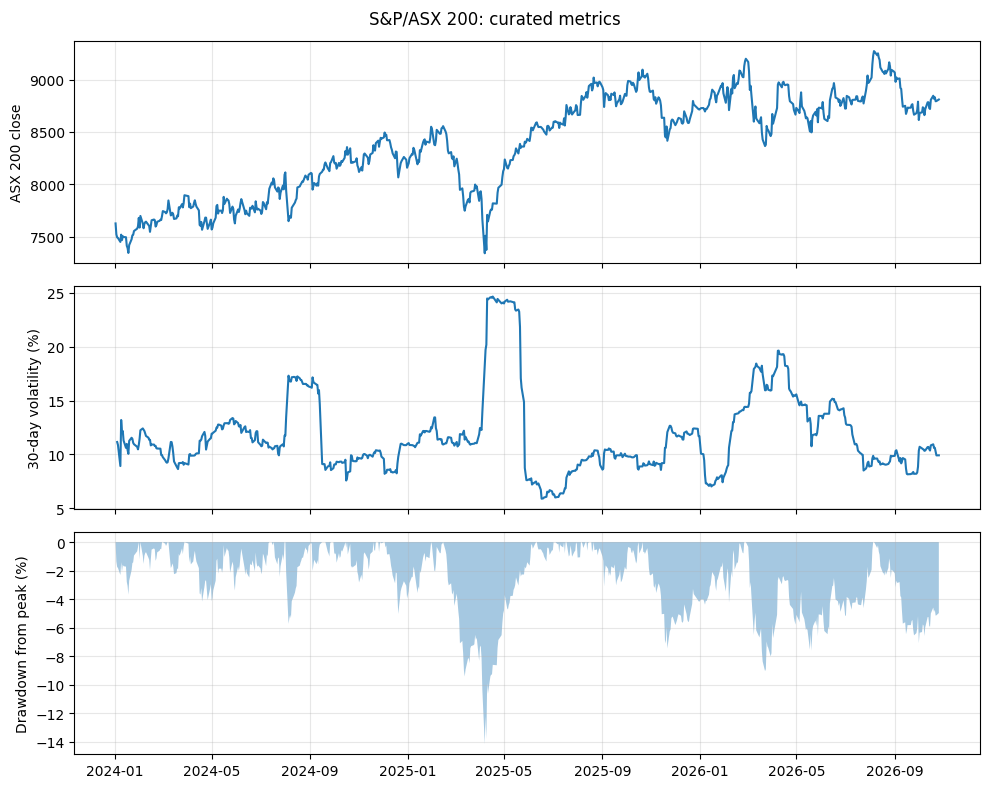

In [17]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(3, 1, figsize=(10, 8), sharex=True)
ax[0].plot(m["date"], m["close"])
ax[0].set_ylabel("ASX 200 close")
ax[1].plot(m["date"], m["vol_30d"] * 100)
ax[1].set_ylabel("30-day volatility (%)")
ax[2].fill_between(m["date"], m["drawdown"] * 100, 0, alpha=0.4)
ax[2].set_ylabel("Drawdown from peak (%)")
for a in ax:
    a.grid(alpha=0.3)
fig.suptitle("S&P/ASX 200: curated metrics")
plt.tight_layout()
plt.show()

In [18]:
worst = m.loc[m["drawdown"].idxmin()]
print("Worst drawdown:", round(worst["drawdown"] * 100, 1), "% on", worst["date"].date())

Worst drawdown: -14.2 % on 2025-04-07
